Implement kruskal's algorithm

In [4]:
import time


# Find operation with path compression
def find(parent, vertex):
    if parent[vertex] != vertex:
        parent[vertex] = find(parent, parent[vertex])
    return parent[vertex]


# Union operation
def union(parent, rank, u, v):
    root_u = find(parent, u)
    root_v = find(parent, v)

    if root_u != root_v:
        # Union by rank
        if rank[root_u] < rank[root_v]:
            parent[root_u] = root_v
        elif rank[root_u] > rank[root_v]:
            parent[root_v] = root_u
        else:
            parent[root_v] = root_u
            rank[root_u] += 1


def kruskal(vertices, edges):
    # Sort edges according to weight
    edges.sort(key=lambda x: x[2])

    parent = {vertex: vertex for vertex in vertices}
    rank = {vertex: 0 for vertex in vertices}

    mst = []
    total_weight = 0

    for u, v, weight in edges:
        # Check whether adding this edge creates a cycle
        if find(parent, u) != find(parent, v):
            union(parent, rank, u, v)

            mst.append((u, v, weight))
            total_weight += weight

            # MST contains V-1 edges
            if len(mst) == len(vertices) - 1:
                break

    return mst, total_weight


# ---------------- MAIN PROGRAM ----------------

print("Kruskal's Algorithm - Minimum Spanning Tree")

# Number of vertices
n = int(input("Enter number of vertices: "))

vertices = []

print("Enter vertex names:")
for i in range(n):
    vertex = input(f"Vertex {i + 1}: ")
    vertices.append(vertex)

# Number of edges
m = int(input("\nEnter number of edges: "))

edges = []

print("\nEnter edges in the format: source destination weight")

for i in range(m):
    u, v, weight = input(f"Edge {i + 1}: ").split()
    edges.append((u, v, int(weight)))


# Measure execution time
start_time = time.perf_counter()

mst, total_weight = kruskal(vertices, edges)

end_time = time.perf_counter()

execution_time = end_time - start_time


# Display result
print("\n---------- Minimum Spanning Tree ----------")

if len(mst) != n - 1:
    print("MST cannot be formed because the graph is disconnected.")
else:
    for u, v, weight in mst:
        print(f"{u} -- {v}  Weight: {weight}")

    print(f"\nTotal MST Weight: {total_weight}")

print(f"Execution Time: {execution_time:.9f} seconds")

print("\n---------- Complexity ----------")
print("Time Complexity : O(E log E)")
print("Space Complexity: O(V + E)")


Kruskal's Algorithm - Minimum Spanning Tree
Enter number of vertices: 5
Enter vertex names:
Vertex 1: A
Vertex 2: B
Vertex 3: C
Vertex 4: D
Vertex 5: E

Enter number of edges: 5

Enter edges in the format: source destination weight
Edge 1: A B 10
Edge 2: B C 3
Edge 3: C D 8
Edge 4: D E 6
Edge 5: E A  3

---------- Minimum Spanning Tree ----------
B -- C  Weight: 3
E -- A  Weight: 3
D -- E  Weight: 6
C -- D  Weight: 8

Total MST Weight: 20
Execution Time: 0.000123981 seconds

---------- Complexity ----------
Time Complexity : O(E log E)
Space Complexity: O(V + E)


Output:

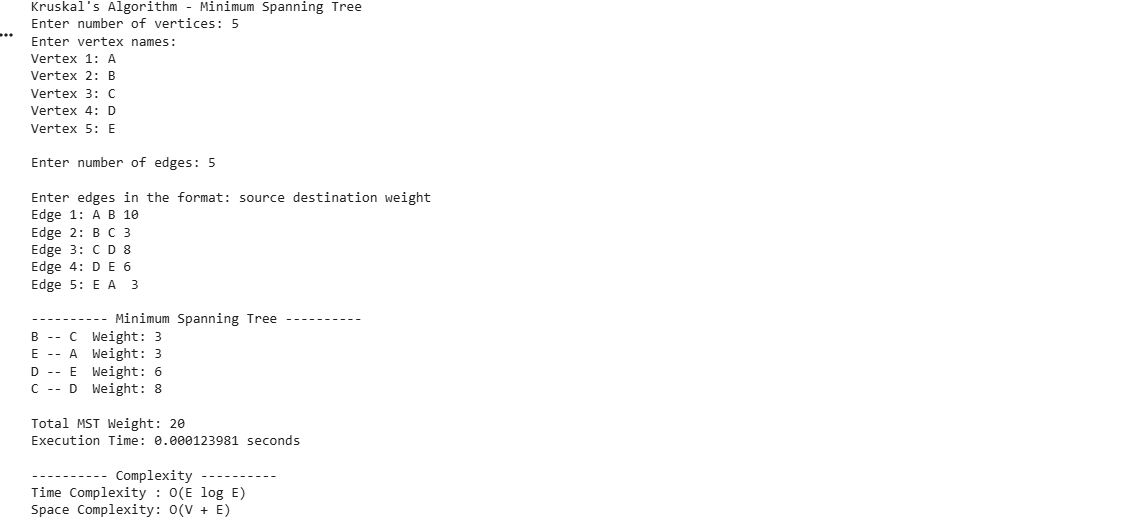

Readme:


Kruskal’s Algorithm finds the Minimum Spanning Tree (MST) of a weighted graph using sorting and Union-Find.
The program accepts user input, displays the MST and total weight, measures execution time, and has O(E log E) time and O(V + E) space complexity.